# Real Data Integration: Temperature and GPS Alignment

**Purpose:** prepare traceable field observations for subsequent GP tests. This report reads the saved processing outputs. Original data, assumptions and reproduction instructions are documented in the [README](README.md).

**Clock alignment remains unverified.** EST is converted to UTC and zero additional sensor-clock offset is assumed. Numerical processing checks do not establish physical synchronization.

In [1]:
from pathlib import Path
import csv, json, hashlib, html
from IPython.display import display, HTML, Image
root=Path.cwd()
if not (root/'result'/'summary.json').exists():
    raise RuntimeError('Run this notebook from the Real_Data_Integration folder.')
result=root/'result'
s=json.loads((result/'summary.json').read_text(encoding='utf-8'))
v=json.loads((result/'verification.json').read_text(encoding='utf-8'))
with (result/'gp_samples.csv').open(encoding='utf-8',newline='') as f:
    samples=list(csv.DictReader(f))
def table(headers, rows):
    def row(values,tag):
        return '<tr>'+''.join(f'<{tag}>{html.escape(str(x))}</{tag}>' for x in values)+'</tr>'
    display(HTML('<table>'+row(headers,'th')+''.join(row(r,'td') for r in rows)+'</table>'))
table(['Measure','Result'],[
    ['Run',s['run_id']],['Temperature / valid GPS',f"{s['temperature_count']} / {s['valid_gps_count']}"],
    ['Matched / before / after',f"{s['matched_count']} / {s['alignment_counts'].get('before_gps',0)} / {s['alignment_counts'].get('after_gps',0)}"],
    ['Matched UTC interval',s['matched_start_utc']+' to '+s['matched_end_utc']],
    ['Extent east × north (m)',str([round(x,2) for x in s['gps_extent_east_north_m']])],
    ['Recorded horizontal path (m)',round(s['horizontal_path_length_m'],2)],
    ['Processing checks passed',v['tests_run'] if v['passed'] else 'FAILED'],
    ['Physical clock alignment verified',s['assumptions']['clock_alignment_verified']]])
fields=['sample_id','timestamp_utc','t_s','x_east_m','y_north_m','temperature_c']
table(fields,[[r[k] if k in fields[:2] else f'{float(r[k]):.4f}' for k in fields] for r in samples[:3]+samples[-3:]])

Measure,Result
Run,nov-3-baseball-1
Temperature / valid GPS,1100 / 981
Matched / before / after,980 / 63 / 57
Matched UTC interval,2026-11-03T19:24:16.000000000Z to 2026-11-03T19:40:35.000000000Z
Extent east × north (m),"[97.51, 63.55]"
Recorded horizontal path (m),1028.37
Processing checks passed,8
Physical clock alignment verified,False


sample_id,timestamp_utc,t_s,x_east_m,y_north_m,temperature_c
64,2026-11-03T19:24:16.000000000Z,0.6745,-0.0000,-0.0000,26.5097
65,2026-11-03T19:24:17.000000000Z,1.6745,-0.0000,-0.0000,26.5526
66,2026-11-03T19:24:18.000000000Z,2.6745,-0.0000,0.0000,26.5526
1041,2026-11-03T19:40:33.000000000Z,977.6745,88.3341,14.9989,26.7671
1042,2026-11-03T19:40:34.000000000Z,978.6745,88.3341,14.9989,26.7671
1043,2026-11-03T19:40:35.000000000Z,979.6745,88.3341,14.9989,26.7242


## Measured trajectory and temperature

Colour represents temperature assigned at the assumed synchronized timestamp. The trajectory is in local ENU metres. This is a plot of recorded samples, not a reconstructed temperature field or navigation map.

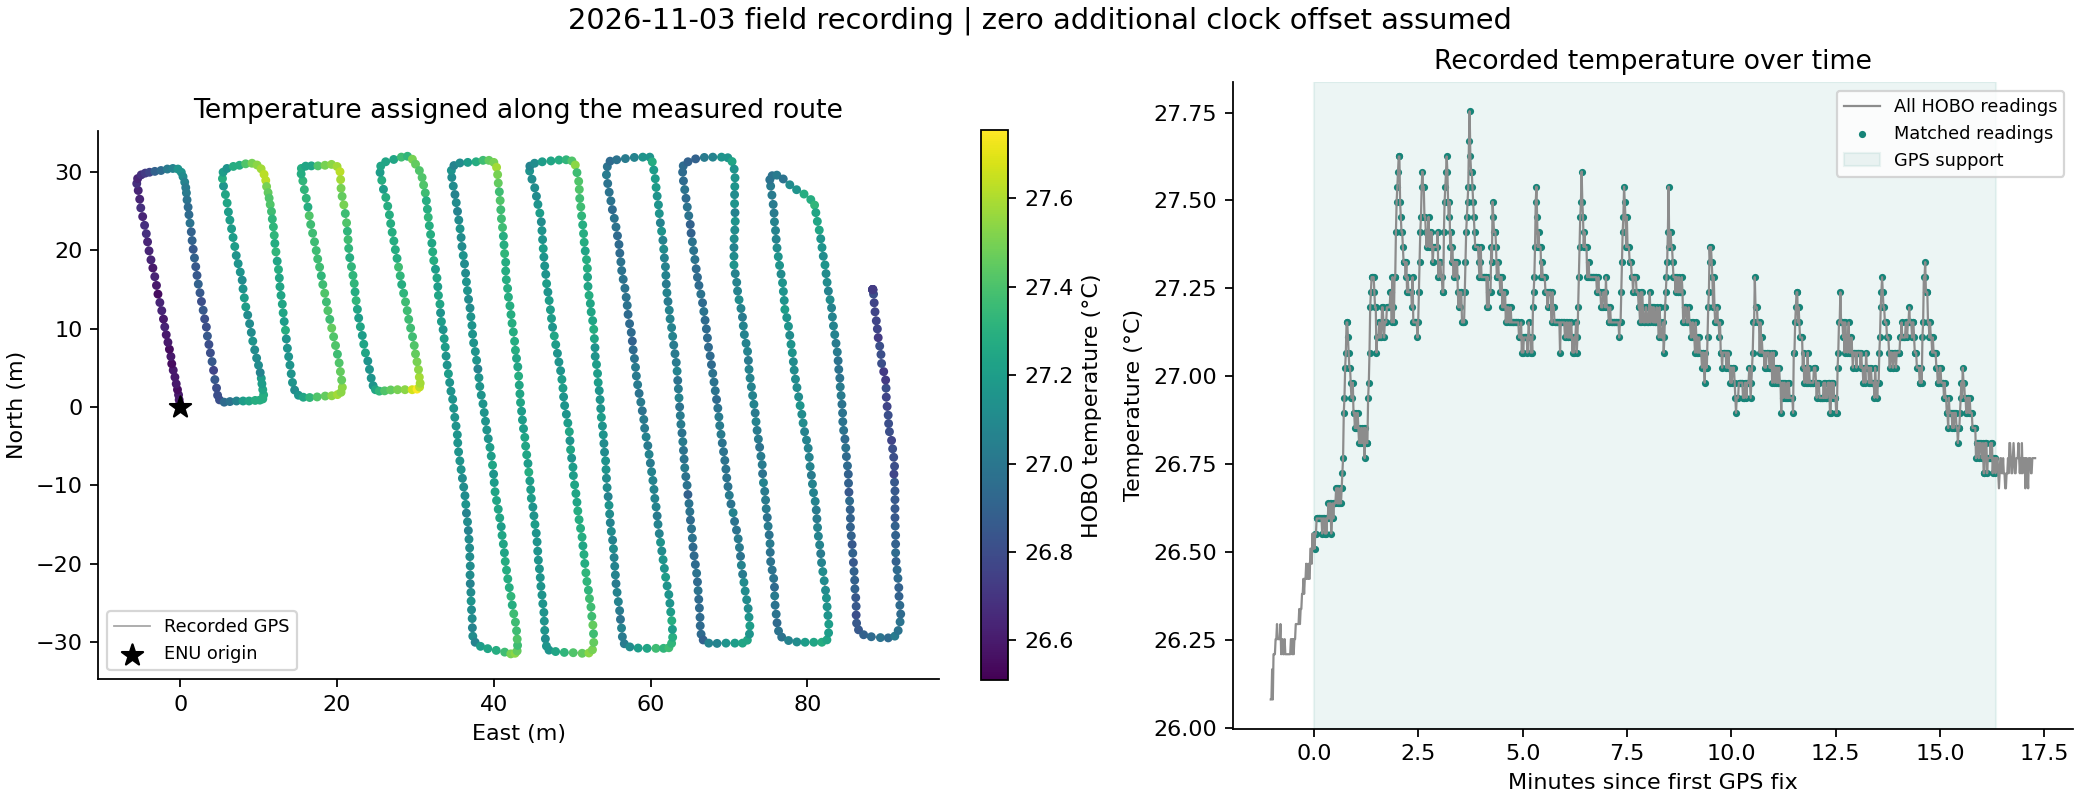

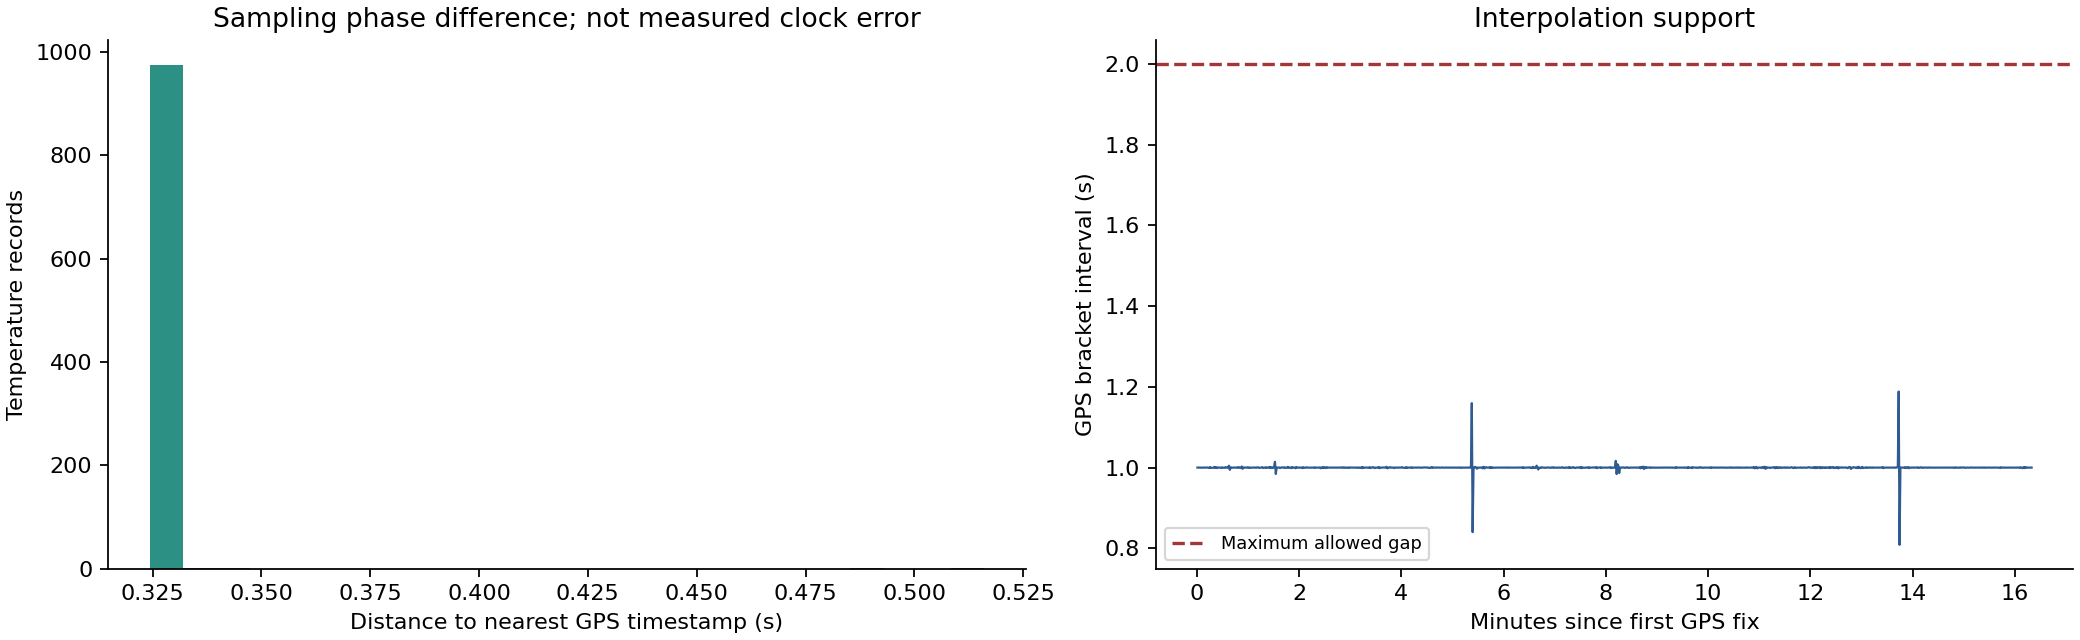

In [2]:
display(Image(filename=str(result/'figures'/'trajectory_temperature.png'), embed=True))
display(Image(filename=str(result/'figures'/'alignment_diagnostics.png'), embed=True))

## Sensitivity and validation

The following diagnostic shifts temperature timestamps by hypothetical offsets and recomputes positions. It shows the effect of timing uncertainty; it neither estimates the true offset nor supplies a calibrated error bound. Nearest-sample time distance and bag receipt latency cannot verify the HOBO clock.

In [3]:
table(['Hypothetical extra offset (s)','Comparable rows','Median position change (m)','Maximum change (m)'],
      [[r['assumed_extra_offset_s'],r['comparable_samples'],
        round(r['horizontal_displacement_m']['median'],3),round(r['horizontal_displacement_m']['max'],3)]
       for r in s['offset_sensitivity']])
m=json.loads((result/'manifest.json').read_text(encoding='utf-8'))
for name,expected in m['outputs'].items():
    assert hashlib.sha256((result/name).read_bytes()).hexdigest()==expected, name
assert v['passed'] and len(samples)==s['matched_count']
assert all(r['clock_alignment_verified']=='False' for r in samples)
print('All saved data-product hashes match. All matched rows retain the unverified-clock flag.')
print('Executed checks:')
print('\n'.join(v['test_names']))

Hypothetical extra offset (s),Comparable rows,Median position change (m),Maximum change (m)
-2.0,978,2.234,2.404
-1.0,979,1.116,1.225
1.0,979,1.116,1.225
2.0,978,2.234,2.404


All saved data-product hashes match. All matched rows retain the unverified-clock flag.
Executed checks:
test_actual_coordinate_scale_against_local_ellipsoid_differential
test_actual_counts_and_source_temperature_preservation
test_actual_interpolation_against_numpy_and_bracket_provenance
test_enu_against_analytic_equator_geometry
test_est_conversion_and_offset_sign
test_invalid_fix_and_gap_are_not_bridged
test_nanosecond_precision_and_exact_boundaries
test_output_hashes_and_unverified_clock_flag


## Conclusion

- **980 matched observations** are available for initial GP data work under the recorded clock assumption. The other 120 temperatures remain in the alignment audit with exclusion reasons.
- Recorded geometry spans approximately **97.5 × 63.5 m**. Do not rescale these physical coordinates to an earlier synthetic map.
- Clock offset, thermal response delay and the sensor mounting offset remain unverified. Confirm the clock procedure/common event before treating spatial associations as validated.
- One moving run does not separate temporal drift from spatial structure. No kernel fitting, policy ranking, field reconstruction or ROS navigation was executed.
- Next: resolve timing evidence and run an initial GP evaluation with held-out route/time blocks. A map-frame registration and navigable map will be needed separately for physical navigation.